# Assignment #4


# 1. Basics of Geostatistics (25 pts)

Each observation of an environmental variable in space $z(\mathbf{x})$ can be interpreted as a single realization of a random variable $Z(\mathbf{x})$. Where $\mathbf{x}$ denotes the position in space of the observation. In a given finite region there can be an infinite number of locations $\mathbf{x}$ and thus an infinite number of random variables $Z(\mathbf{x})$. The set of all these random variables $Z(\mathbf{x})$ constitutes a random process. For the remainder of this problem assume $Z_i = Z(\mathbf{x})$ and $z_i = z(\mathbf{x})$.

A. Explain the difference between $z_i$ and $Z_i$.

B. Based on the lectures, define $Z^*$ and $Z_0$. Explain the difference between the two. 

C. Describe the meaning of $\text{Cov}(Z_i,Z_j)$, $\text{Cov}(Z_i,Z_0)$, $\text{Var}(Z_0)$.

D. The Simple Kriging system is given by $\Sigma \mathbf{w} = \mathbf{c}$. Explain each term in that equation.

E. Once $\mathbf{w}$ is computed, how can it be used to estimate $z^*$? 

F. What is second-order stationarity?

G. Assuming second-order stationarity, if we are interested in the covariance between $Z_i$ and $Z_j$, why do we concern ourselves with the semivariogram?

H. Starting from the definition of covariance, derive the relationship between covariance and semivariogram. 

A \(Z_i\) is a random variable representing the environmental value at location \(i\), while \(z_i\) is an observed realization of that random variable.

B \(Z_0\) is the random variable at the target location, while \(Z^*\) is the Kriging predictor constructed from observed locations. Their difference represents prediction error.

CCov(\(Z_i,Z_j\)) measures the spatial dependence between two observed locations. Cov(\(Z_i,Z_0\)) measures the dependence between an observed location and the target location. Var(\(Z_0\)) measures the variability of the random variable at the target location.

D\(\Sigma\) is the covariance matrix among observed locations, \(w\) is the vector of unknown Kriging weights, and \(c\) is the covariance vector between observed locations and the target location. Solving the system gives the optimal weights that minimize prediction error variance.

EThe Kriging weights are applied to the observed values to obtain the prediction. For Simple Kriging with a known mean \(\mu\), the estimated value is \(z^*=\mu+\sum_i w_i(z_i-\mu)\).

FSecond-order stationarity means that the mean is constant over space and the covariance between two locations depends only on their spatial separation (lag), not their absolute positions.

GThe semivariogram describes spatial dependence based on the differences between observations. Under second-order stationarity, the semivariogram and covariance are related by \(\gamma(h)=C(0)-C(h)\). Therefore, we can use the semivariogram to model the covariance structure needed for Kriging.



In [5]:

from IPython.display import display, Markdown

display(Markdown(r"""
### H. Relationship Between Covariance and Semivariogram

The covariance is defined as:

$$
\operatorname{Cov}(Z_i,Z_j)
= E[(Z_i-\mu)(Z_j-\mu)]
= E[Z_iZ_j]-\mu^2
$$

Under second-order stationarity:

$$
E[Z_i]=E[Z_j]=\mu
$$

$$
\operatorname{Var}(Z_i)=\operatorname{Var}(Z_j)=C(0)
$$

The semivariogram is defined as:

$$
\gamma(h)=\frac{1}{2}E[(Z_i-Z_j)^2]
$$

Expanding:

$$
\gamma(h)=\frac{1}{2}
\left[E[Z_i^2]+E[Z_j^2]-2E[Z_iZ_j]\right]
$$

Since:

$$
E[Z_i^2]=E[Z_j^2]=C(0)+\mu^2
$$

$$
E[Z_iZ_j]=C(h)+\mu^2
$$

Substituting:

$$
\gamma(h)=\frac{1}{2}
[2C(0)+2\mu^2-2C(h)-2\mu^2]
$$

Therefore:

$$
\boxed{\gamma(h)=C(0)-C(h)}
$$

Thus, under second-order stationarity, the semivariogram equals the variance minus the covariance at spatial lag h.
"""))



### H. Relationship Between Covariance and Semivariogram

The covariance is defined as:

$$
\operatorname{Cov}(Z_i,Z_j)
= E[(Z_i-\mu)(Z_j-\mu)]
= E[Z_iZ_j]-\mu^2
$$

Under second-order stationarity:

$$
E[Z_i]=E[Z_j]=\mu
$$

$$
\operatorname{Var}(Z_i)=\operatorname{Var}(Z_j)=C(0)
$$

The semivariogram is defined as:

$$
\gamma(h)=\frac{1}{2}E[(Z_i-Z_j)^2]
$$

Expanding:

$$
\gamma(h)=\frac{1}{2}
\left[E[Z_i^2]+E[Z_j^2]-2E[Z_iZ_j]\right]
$$

Since:

$$
E[Z_i^2]=E[Z_j^2]=C(0)+\mu^2
$$

$$
E[Z_iZ_j]=C(h)+\mu^2
$$

Substituting:

$$
\gamma(h)=\frac{1}{2}
[2C(0)+2\mu^2-2C(h)-2\mu^2]
$$

Therefore:

$$
\boxed{\gamma(h)=C(0)-C(h)}
$$

Thus, under second-order stationarity, the semivariogram equals the variance minus the covariance at spatial lag h.


# 2. Computing the semivariogram (25 pts)

Using data from the samples group in `/data/HW/HW4/HW4.nc`:

A. Assemble the isotropic cloud semivariogram. Plot the results. Only consider distances up to 25000 m. 

B. Having computed the cloud semivariogram, assemble the sample semivariogram using a bin size of 500 m. Plot the results. Only consider distances up to 25000 m.

C. Fit an exponential, spherical, and bounded linear semivariogram to the sample semivariogram. Compute the $R^2$ of each fit then plot the results. Remember to set bounds for the curve fitting, if not it won't converge. Based on your results, which model semivariogram would you use for the region?

<xarray.Dataset>
Dimensions:  (n: 1396)
Dimensions without coordinates: n
Data variables:
    x        (n) float64 -3.996e+03 -1.3e+04 -4.496e+03 ... 2.254e+03 1.275e+04
    y        (n) float64 -4.463e+03 -9.213e+03 ... 1.354e+04 1.129e+04
    sand     (n) float64 17.72 12.28 16.07 15.04 ... 17.25 14.11 12.57 11.03
Samples: 1396
Variables: x, y, sand


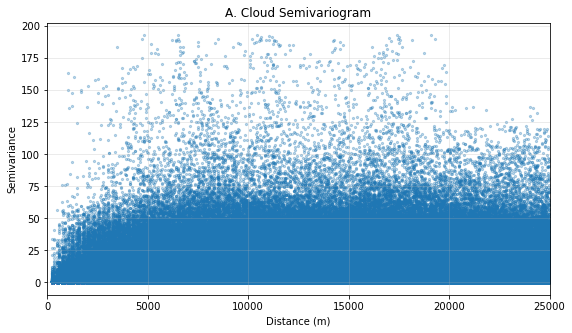

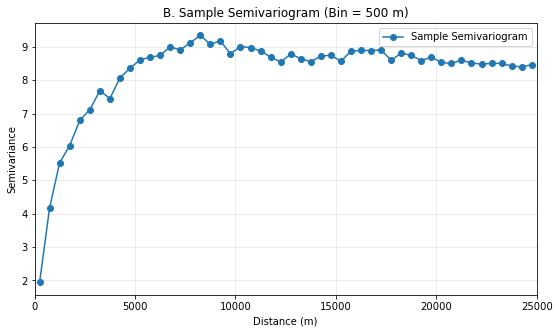

Exponential:
  Nugget = 1.0289
  Partial sill = 7.7127
  Range parameter = 1598.22 m
  R² = 0.9655

Spherical:
  Nugget = 2.4597
  Partial sill = 6.2514
  Range parameter = 4920.18 m
  R² = 0.9425

Bounded Linear:
  Nugget = 2.9105
  Partial sill = 5.7988
  Range parameter = 3956.34 m
  R² = 0.9220



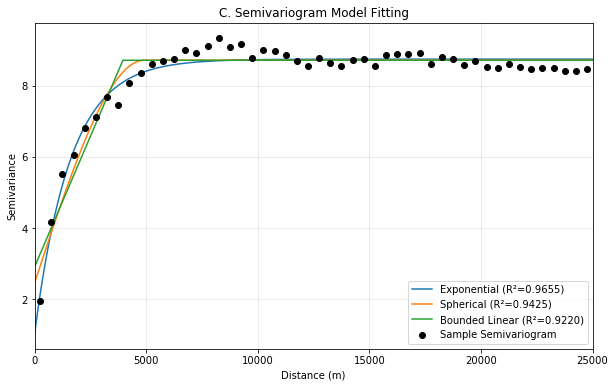

Model comparison:
Exponential: R² = 0.9655
Spherical: R² = 0.9425
Bounded Linear: R² = 0.9220

Best model: Exponential
Highest R²: 0.9655


In [7]:

import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist
from scipy.optimize import curve_fit

# ==================================================
# 1. Load data from the "samples" group
# ==================================================
ds = xr.open_dataset("/data/HW/HW4/HW4.nc", group="samples")
df = ds.to_dataframe().reset_index()

print(ds)

# Automatically identify coordinate and value columns
def find_col(names):
    return next((c for c in df.columns if c.lower() in names), None)

x_col = find_col(["x", "easting", "lon", "longitude", "sample_x"])
y_col = find_col(["y", "northing", "lat", "latitude", "sample_y"])
z_col = find_col(["z", "value", "values", "elevation",
                  "measurement", "sample_z", "data"])

if z_col is None and x_col and y_col:
    candidates = [c for c in ds.data_vars
                  if c not in [x_col, y_col]
                  and np.issubdtype(ds[c].dtype, np.number)]
    if len(candidates) == 1:
        z_col = candidates[0]

if not all([x_col, y_col, z_col]):
    raise ValueError(f"Check variable names: {list(df.columns)}")

df = df[[x_col, y_col, z_col]].dropna()

x = df["x"].values.astype(float)
y = df["y"].values.astype(float)
z = df["sand"].values.astype(float)

# Convert geographic coordinates from degrees to approximate meters
if x_col.lower() in ["lon", "longitude"] and y_col.lower() in ["lat", "latitude"]:
    R = 6371000
    x = R * np.deg2rad(x) * np.cos(np.deg2rad(np.mean(y)))
    y = R * np.deg2rad(y)

print(f"Samples: {len(z)}")
print(f"Variables: {x_col}, {y_col}, {z_col}")

# ==================================================
# A. Cloud semivariogram
# ==================================================
coords = np.column_stack((x, y))

# Calculate pairwise distance and semivariance
h = pdist(coords)
gamma = 0.5 * pdist(z.reshape(-1, 1), metric="sqeuclidean")

# Keep distances up to 25000 m
mask = h <= 25000
h = h[mask]
gamma = gamma[mask]

plt.figure(figsize=(9, 5))
plt.scatter(h, gamma, s=5, alpha=0.3)
plt.xlabel("Distance (m)")
plt.ylabel("Semivariance")
plt.title("A. Cloud Semivariogram")
plt.xlim(0, 25000)
plt.grid(alpha=0.3)
plt.show()

# ==================================================
# B. Sample semivariogram (500 m bins)
# ==================================================
bins = np.arange(0, 25001, 500)
centers = (bins[:-1] + bins[1:]) / 2

counts, _ = np.histogram(h, bins=bins)
sums, _ = np.histogram(h, bins=bins, weights=gamma)

# Calculate mean semivariance in each bin
valid = counts > 0
lag = centers[valid]
gamma_bin = sums[valid] / counts[valid]

plt.figure(figsize=(9, 5))
plt.plot(lag, gamma_bin, "o-", label="Sample Semivariogram")
plt.xlabel("Distance (m)")
plt.ylabel("Semivariance")
plt.title("B. Sample Semivariogram (Bin = 500 m)")
plt.xlim(0, 25000)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# ==================================================
# C. Fit three semivariogram models
# ==================================================

# Exponential model
def exponential(h, nugget, sill, a):
    return nugget + sill * (1 - np.exp(-h / a))

# Spherical model
def spherical(h, nugget, sill, a):
    r = h / a
    return nugget + sill * np.where(
        r < 1, 1.5 * r - 0.5 * r**3, 1
    )

# Bounded linear model
def bounded_linear(h, nugget, sill, a):
    return nugget + sill * np.minimum(h / a, 1)

models = {
    "Exponential": exponential,
    "Spherical": spherical,
    "Bounded Linear": bounded_linear
}

# Initial guesses and parameter bounds
initial = [max(0, gamma_bin.min()),
           max(gamma_bin.max(), 1e-6), 8000]

lower = [0, 0, 1]
upper = [np.inf, np.inf, 100000]

results = {}
h_plot = np.linspace(0, 25000, 500)

plt.figure(figsize=(10, 6))
plt.scatter(lag, gamma_bin, color="black",
            label="Sample Semivariogram", zorder=5)

for name, model in models.items():

    # Fit model with bounds
    params, _ = curve_fit(
        model, lag, gamma_bin,
        p0=initial,
        bounds=(lower, upper),
        maxfev=50000
    )

    # Calculate R-squared
    predicted = model(lag, *params)
    ss_res = np.sum((gamma_bin - predicted)**2)
    ss_tot = np.sum((gamma_bin - np.mean(gamma_bin))**2)
    r2 = 1 - ss_res / ss_tot

    results[name] = r2

    # Plot fitted curve
    plt.plot(h_plot, model(h_plot, *params),
             label=f"{name} (R²={r2:.4f})")

    print(f"{name}:")
    print(f"  Nugget = {params[0]:.4f}")
    print(f"  Partial sill = {params[1]:.4f}")
    print(f"  Range parameter = {params[2]:.2f} m")
    print(f"  R² = {r2:.4f}\n")

plt.xlabel("Distance (m)")
plt.ylabel("Semivariance")
plt.title("C. Semivariogram Model Fitting")
plt.xlim(0, 25000)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# ==================================================
# Select the best model
# ==================================================
best_model = max(results, key=results.get)

print("Model comparison:")
for name, score in results.items():
    print(f"{name}: R² = {score:.4f}")

print(f"\nBest model: {best_model}")
print(f"Highest R²: {results[best_model]:.4f}")


# 3. Ordinary Kriging (25 pts)

Using the data in the samples group in '/data/HW/HW4/HW4.nc', and assumming an exponential semivariogram with a sill ($c$) of 10.0 $\%^2$, a nugget of 0, and a range ($a$) of 1500 m, do the following:

A. Use ordinary kriging to try to reproduce the original map of sand (as found in the original_data group in `/data/HW/HW4/HW4.nc`).

B. Plot the reproduced map and the original map. Compare the two via the $R^2$.

C. Compute the estimated mean squared error at each grid cell (kriging variance) and plot the map. Discuss the results. 

D. One of the largest limitations of Kriging is that the observation covariance matrix can become too large. Another more practical approach is to only use the closest $n$ points to each point to which we interpolate. Setting $n = 10$, perform this "localized" ordinary kriging and compare the results to those from part B. 

E. Repeat part D. However, this time set $n=1$. What other deterministic spatial interpolation method does this now mimic?

Original data:
<xarray.Dataset>
Dimensions:  (x: 105, y: 133)
Coordinates:
  * x        (x) float64 -1.3e+04 -1.275e+04 -1.25e+04 ... 1.275e+04 1.3e+04
  * y        (y) float64 1.654e+04 1.629e+04 1.604e+04 ... -1.621e+04 -1.646e+04
Data variables:
    sand     (y, x) float64 ...
Number of samples: 1396
Number of grid cells: 13965
Global Ordinary Kriging R² = 0.6107


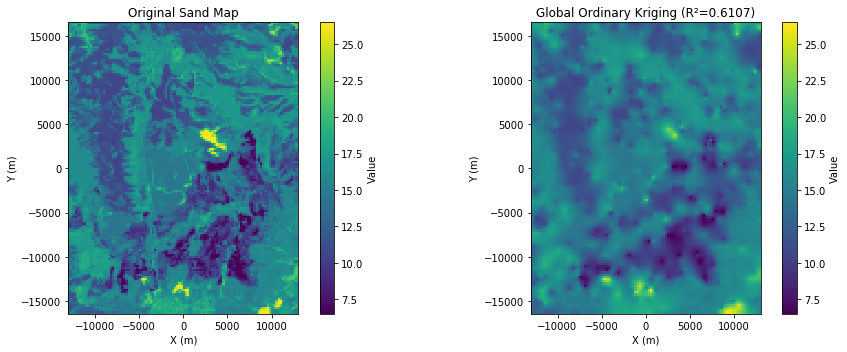

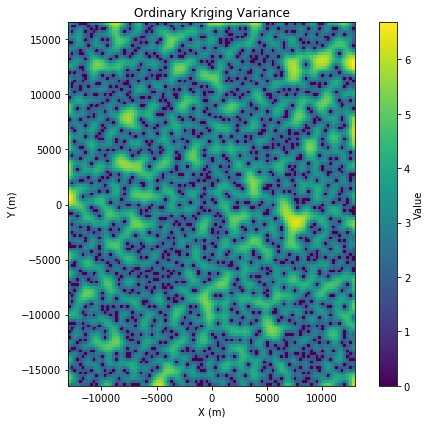

Mean Kriging Variance: 2.755
Maximum Kriging Variance: 7.1833


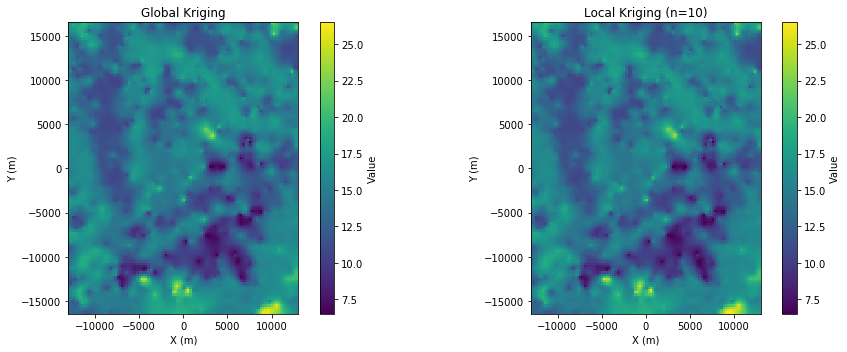

Global Kriging R²: 0.6107
Local Kriging (n=10) R²: 0.6107


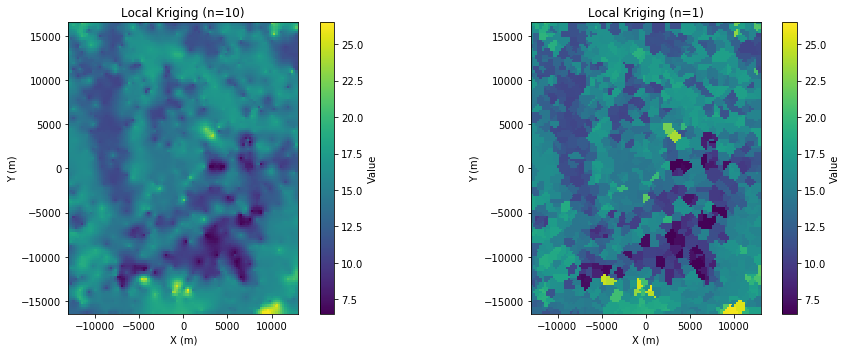

Local Kriging (n=1) R²: 0.4089
This is equivalent to Nearest Neighbor Interpolation.

===== FINAL RESULTS =====
Global Ordinary Kriging: R² = 0.6107
Local Kriging (n=10):    R² = 0.6107
Local Kriging (n=1):     R² = 0.4089


In [9]:

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from scipy.spatial.distance import cdist
from scipy.linalg import cho_factor, cho_solve, solve_triangular

# ==================================================
# 1. Load sample and original data
# ==================================================
path = "/data/HW/HW4/HW4.nc"

samples = xr.open_dataset(path, group="samples")
original = xr.open_dataset(path, group="original_data")

print("Original data:")
print(original)

# Sample coordinates and sand content
sx = samples["x"].values.astype(float)
sy = samples["y"].values.astype(float)
sz = samples["sand"].values.astype(float)

good = np.isfinite(sx) & np.isfinite(sy) & np.isfinite(sz)
coords = np.column_stack((sx[good], sy[good]))
z = sz[good]

# Original map and grid coordinates
sand_da = original["sand"].squeeze()
dims = sand_da.dims
true_map = sand_da.values.astype(float)

X = xr.broadcast(original["x"], sand_da)[0].transpose(*dims).values
Y = xr.broadcast(original["y"], sand_da)[0].transpose(*dims).values

# Locations at which to make predictions
grid_mask = np.isfinite(X) & np.isfinite(Y)
grid_xy = np.column_stack((X[grid_mask], Y[grid_mask]))

def to_map(values):
    result = np.full(true_map.shape, np.nan)
    result[grid_mask] = values
    return result

def r2_score(y_true, y_pred):
    valid = np.isfinite(y_true) & np.isfinite(y_pred)
    a = y_true[valid]
    b = y_pred[valid]
    return 1 - np.sum((a-b)**2) / np.sum((a-np.mean(a))**2)

def plot_map(ax, data, title, vmin=None, vmax=None, cmap="viridis"):
    if data.ndim == 2:
        try:
            m = ax.pcolormesh(X, Y, data, shading="auto",
                              cmap=cmap, vmin=vmin, vmax=vmax)
        except (ValueError, TypeError):
            m = ax.scatter(X[grid_mask], Y[grid_mask],
                           c=data[grid_mask], s=5,
                           cmap=cmap, vmin=vmin, vmax=vmax)
    else:
        m = ax.scatter(X[grid_mask], Y[grid_mask],
                       c=data[grid_mask], s=5,
                       cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(title)
    ax.set_xlabel("X (m)")
    ax.set_ylabel("Y (m)")
    ax.set_aspect("equal")
    plt.colorbar(m, ax=ax, label="Value")

print("Number of samples:", len(z))
print("Number of grid cells:", len(grid_xy))

# ==================================================
# 2. Given exponential semivariogram
# ==================================================
sill = 10.0
nugget = 0.0
a = 1500.0

# gamma(h) = 10 * (1 - exp(-h/1500))
def semivariogram(h):
    return sill * (1 - np.exp(-h/a))

# Equivalent covariance function
def covariance(h):
    return sill * np.exp(-h/a)

# ==================================================
# A. Global Ordinary Kriging
# ==================================================
n = len(z)

# Covariance matrix among all sample points
C = covariance(cdist(coords, coords))

# Cholesky decomposition for efficient calculation
factor = cho_factor(C, lower=True)

ones = np.ones(n)
u = cho_solve(factor, ones)
v = cho_solve(factor, z)

denom = np.dot(ones, u)
mean_est = np.dot(ones, v) / denom
alpha = v - u * mean_est

pred = np.empty(len(grid_xy))
variance = np.empty(len(grid_xy))

# Process the grid in batches to reduce memory usage
batch_size = 400

for start in range(0, len(grid_xy), batch_size):
    end = min(start + batch_size, len(grid_xy))
    points = grid_xy[start:end]

    # Covariance between samples and prediction locations
    c = covariance(cdist(coords, points))

    # Ordinary Kriging prediction
    pred[start:end] = mean_est + np.dot(alpha, c)

    # Ordinary Kriging prediction variance
    L = solve_triangular(factor[0], c, lower=True)
    variance[start:end] = (
        sill - np.sum(L**2, axis=0)
        + (1 - np.dot(u, c))**2 / denom
    )

pred_map = to_map(pred)
variance_map = to_map(np.maximum(variance, 0))

# ==================================================
# B. Compare original and reproduced maps
# ==================================================
r2_global = r2_score(true_map, pred_map)
print("Global Ordinary Kriging R² =", round(r2_global, 4))

vmin = np.nanmin(true_map)
vmax = np.nanmax(true_map)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

plot_map(axes[0], true_map, "Original Sand Map", vmin, vmax)
plot_map(axes[1], pred_map,
         "Global Ordinary Kriging (R²={:.4f})".format(r2_global),
         vmin, vmax)

plt.tight_layout()
plt.show()

# ==================================================
# C. Kriging variance map
# ==================================================
fig, ax = plt.subplots(figsize=(7, 6))
plot_map(ax, variance_map, "Ordinary Kriging Variance",
         cmap="viridis")
plt.tight_layout()
plt.show()

print("Mean Kriging Variance:", round(np.mean(variance), 4))
print("Maximum Kriging Variance:", round(np.max(variance), 4))

# ==================================================
# D. Localized Ordinary Kriging (n = 10)
# ==================================================
tree = cKDTree(coords)

def local_kriging(k):
    predictions = np.empty(len(grid_xy))
    variances = np.empty(len(grid_xy))

    for start in range(0, len(grid_xy), 500):
        end = min(start + 500, len(grid_xy))
        points = grid_xy[start:end]

        # Find the k nearest sample points
        distances, indices = tree.query(points, k=k)

        if k == 1:
            predictions[start:end] = z[indices]
            variances[start:end] = 2 * semivariogram(distances)
            continue

        nearest = coords[indices]
        values = z[indices]
        b = len(points)

        # Pairwise distances within each local neighborhood
        d = np.linalg.norm(
            nearest[:, :, None, :] - nearest[:, None, :, :],
            axis=3
        )

        # Ordinary Kriging matrix with Lagrange multiplier
        K = np.zeros((b, k+1, k+1))
        K[:, :k, :k] = covariance(d)
        K[:, :k, k] = 1
        K[:, k, :k] = 1

        # Covariance to each prediction location
        d0 = np.linalg.norm(nearest - points[:, None, :], axis=2)
        c0 = covariance(d0)

        rhs = np.ones((b, k+1))
        rhs[:, :k] = c0

        # Solve for weights and Lagrange multipliers
        solution = np.linalg.solve(K, rhs)
        weights = solution[:, :k]
        mu = solution[:, k]

        predictions[start:end] = np.sum(weights * values, axis=1)
        variances[start:end] = (
            sill - np.sum(weights * c0, axis=1) - mu
        )

    return predictions, variances

pred10, var10 = local_kriging(10)
map10 = to_map(pred10)
r2_10 = r2_score(true_map, map10)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_map(axes[0], pred_map, "Global Kriging", vmin, vmax)
plot_map(axes[1], map10, "Local Kriging (n=10)",
         vmin, vmax)
plt.tight_layout()
plt.show()

print("Global Kriging R²:", round(r2_global, 4))
print("Local Kriging (n=10) R²:", round(r2_10, 4))

# ==================================================
# E. Localized Kriging (n = 1)
# ==================================================
pred1, var1 = local_kriging(1)
map1 = to_map(pred1)
r2_1 = r2_score(true_map, map1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_map(axes[0], map10, "Local Kriging (n=10)", vmin, vmax)
plot_map(axes[1], map1, "Local Kriging (n=1)", vmin, vmax)
plt.tight_layout()
plt.show()

print("Local Kriging (n=1) R²:", round(r2_1, 4))
print("This is equivalent to Nearest Neighbor Interpolation.")

# ==================================================
# Final R² comparison
# ==================================================
print("\n===== FINAL RESULTS =====")
print("Global Ordinary Kriging: R² =", round(r2_global, 4))
print("Local Kriging (n=10):    R² =", round(r2_10, 4))
print("Local Kriging (n=1):     R² =", round(r2_1, 4))


# 4. Calculate upslope drainage area (25 pts)

Using the elevation data found in `/data/HW/HW4/mtdiablo_dem_sf.tif`, show that the upslope drainage area flowing out of the grid cell point i = 582 and j = 779 is 12,856,300 $m^2$. You will need to write up your own recursive algorithm to estimate upslope drainage area for this problem. You will want to use the d8 flow direction approach. In other words, assume that if a ball is dropped on a given grid cell it will follow the path of steepest descent (i.e., the highest slope) to one (and only one) adjacent cell. Note that the pixel size is 10 meters by 10 meters. Furthermore, you may assume that this data has already been sink-filled.